# 03 · Validation & correction-factor calibration
Rules: (1) fit on **lab/literature** data only, (2) report on the **held-out tube** data, (3) add one correction at a time and keep it only if held-out error drops *and* the parameter is physically sensible.

⚠️ Below runs on **synthetic placeholder data** (`synthetic_demo`) purely to test the pipeline. Replace with real CSVs before drawing any conclusion.

In [1]:
import sys; sys.path.insert(0,'.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from orthocut import *; from calibrate import *
mat = Material('Al 7050', 303, 505)

## 1. Load data
Real data: build `data/lab_oblique.csv`, `data/tube_heldout.csv`, `data/literature.csv` with columns `source, Vc_m_min, t_mm, w_mm, gamma0_deg, Pz_N, Pxy_N`.
Lab (oblique) mapping: Pz ← Ftc (=Fz), Pxy ← √(Frc²+Ffc²) as a first approximation; note i=5° makes this approximate, which is itself a documented error source.

In [2]:
df = synthetic_demo()   # <-- replace: df = pd.concat([pd.read_csv(p) for p in ['data/lab_oblique.csv','data/literature.csv','data/tube_heldout.csv']])
train = df[df.source != 'tube_heldout']; test = df[df.source == 'tube_heldout']
print(len(train), 'train rows,', len(test), 'held-out rows')

16 train rows, 12 held-out rows


## 2. Fig-5-style regression: force vs t (slope = K·w, intercept = edge force)

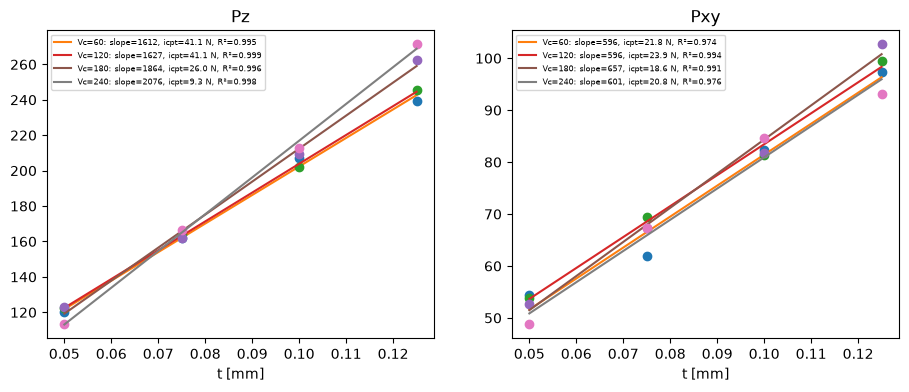

Non-zero intercept => violates slide assumption "tool perfectly sharp / no flank contact" -> edge-force correction Ke


In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
for j,(c,lab) in enumerate([('Pz_N','Pz'),('Pxy_N','Pxy')]):
    for V,g in train.groupby('Vc_m_min'):
        p=np.polyfit(g.t_mm,g[c],1); r2=np.corrcoef(g.t_mm,g[c])[0,1]**2
        ax[j].plot(g.t_mm,g[c],'o'); ax[j].plot(g.t_mm,np.polyval(p,g.t_mm),'-',label=f'Vc={V}: slope={p[0]:.0f}, icpt={p[1]:.1f} N, R²={r2:.3f}')
    ax[j].set_title(lab); ax[j].set_xlabel('t [mm]'); ax[j].legend(fontsize=6)
plt.show()
print('Non-zero intercept => violates slide assumption "tool perfectly sharp / no flank contact" -> edge-force correction Ke')

## 3. Ablation: which corrections earn their place?

In [4]:
sets = {'baseline (mu=0.5)':None, 'mu, tau_k':('mu','tau_k'), '+ edge force':('mu','tau_k','Ke_z','Ke_xy'),
        '+ strain rate':('mu','tau_k','Ke_z','Ke_xy','c_rate'), '+ friction(V)':('mu','tau_k','Ke_z','Ke_xy','c_rate','m_mu')}
rows=[]
for name,free in sets.items():
    p = {'mu':0.5} if free is None else fit(train,mat,free)[0]
    mt,_=metrics(train,mat,p); mh,_=metrics(test,mat,p)
    rows.append({'model':name,'train MAPE Pz':mt['Pz']['MAPE_pct'],'held MAPE Pz':mh['Pz']['MAPE_pct'],'held MAPE Pxy':mh['Pxy']['MAPE_pct'],'held R2 Pz':mh['Pz']['R2'],'params':{k:round(v,3) for k,v in p.items()}})
pd.DataFrame(rows).round(2)

,model,train MAPE Pz,held MAPE Pz,held MAPE Pxy,held R2 Pz,params
0,baseline (mu=0.5),28.82,29.15,57.15,-0.15,{'mu': 0.5}
1,"mu, tau_k",5.66,6.09,11.33,0.95,"{'mu': 0.691, 'tau_k': 1.176}"
2,+ edge force,2.55,1.97,4.24,0.99,"{'mu': 0.621, 'tau_k': 1.059, 'Ke_z': 14.7, 'K..."
3,+ strain rate,2.34,1.57,4.44,1.00,"{'mu': 0.619, 'tau_k': 1.053, 'Ke_z': 14.538, ..."
4,+ friction(V),2.61,1.34,4.28,1.00,"{'mu': 0.628, 'tau_k': 1.037, 'Ke_z': 14.714, ..."


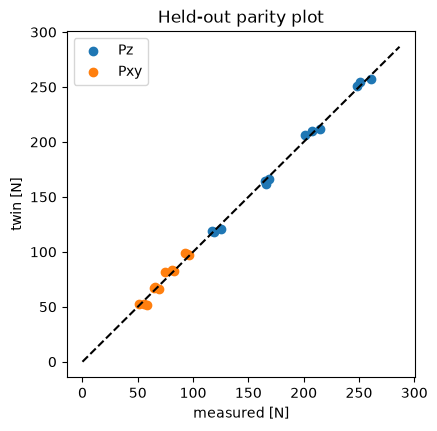

In [5]:
best = fit(train, mat, sets['+ strain rate'])[0]; m, pr = metrics(test, mat, best)
plt.figure(figsize=(4.5,4.5)); plt.scatter(test.Pz_N, pr[:,0], label='Pz'); plt.scatter(test.Pxy_N, pr[:,1], label='Pxy')
lim=max(test.Pz_N.max(),1)*1.1; plt.plot([0,lim],[0,lim],'k--'); plt.xlabel('measured [N]'); plt.ylabel('twin [N]'); plt.legend(); plt.title('Held-out parity plot'); plt.show()

## 4. Caveats to write up honestly
- μ, τ_k and Ke are partly **confounded** (several combinations fit equally well) — report parameter uncertainty (bootstrap) not just point values.
- Lab data are oblique (i=5°, ψ=5°); the tube data are pure orthogonal. Cross-source differences are evidence for/against the obliquity assumption.
- Do not tune on the held-out tube set. Touch it once, at the end.